# Harmonic offset with three lifetimes: what each harmonic contributes
This example explains:
- How the offset rotates the phasor at every harmonic `k` by `k omega t0`, so higher harmonics are rotated more
- How precise each harmonic is, and why that depends on the lifetime.
- How the generalised least-squares combination weights the harmonics differently for each lifetime, and the chi-square test that checks they agree
- The offset map and the corrected phasors and lifetimes of all three wells

<small>Author - Vikas</small>

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2

sys.path.insert(0, "ex_helper")

from sim_general_image import ROIMaskGenerator, WellPlateShape

from pyfli.data_vnp import ColorProcessor, DataViewer
from pyfli.io import DataOperations
from pyfli.phasor.harmonic_offset import HarmonicOffset, correct_phasors, t0_from_h_shift
from pyfli.phasor.phasorS import PhasorAnalyzer
from pyfli.reconstruction import ParamToDecay
from pyfli.reconstruction.common_reconstruct import gate_starts

In [2]:
# Path to the local IRF file
IRF_PATH = "<select file/folder path>"

INFO:pyfli:Initiating IRF load from: <select file/folder path>


Reconstructing decay (vectorized)...


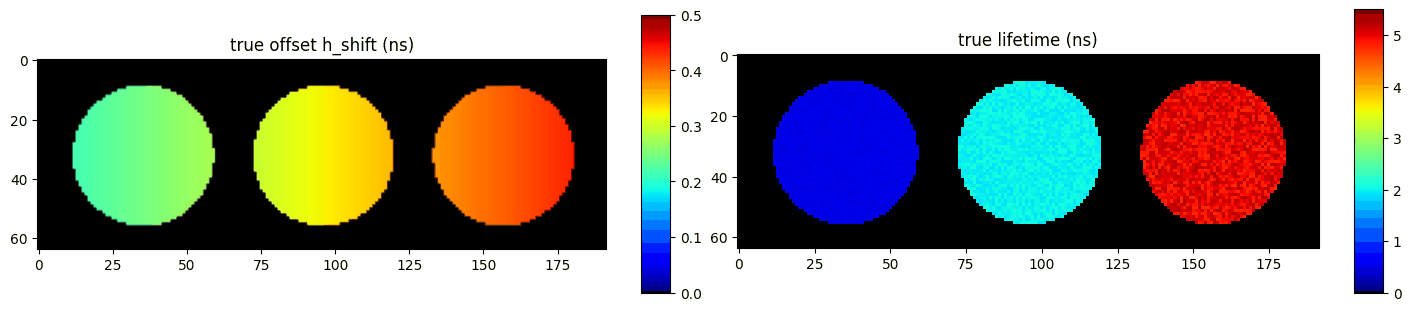

In [3]:
rng = np.random.default_rng()

LASER_HZ = 80e6
PERIOD_NS = 1e9 / LASER_HZ
OMEGA = 2 * np.pi * LASER_HZ * 1e-9
N_HARMONICS = 6

irf = np.clip(np.asarray(DataOperations(irf_path=IRF_PATH).load_irf(), dtype=float)[120, 40, :], 0.0, None)
irf /= irf.sum()
N_BINS = irf.size
t = gate_starts(PERIOD_NS, N_BINS)

generator = ROIMaskGenerator((64, 192), top=5, bottom=5, left=5, right=5)
three_wells = WellPlateShape(rows=1, cols=3, gap=0.12)
img_cluster = generator.generate_cluster_mask(three_wells)
mask = generator.generate_binary_mask(three_wells).astype(bool)
H, W = mask.shape
TAU_WELL = {1: 0.5, 2: 2.0, 3: 5.0}
well_names = {cid: f"well {cid} (tau ~ {tau} ns)" for cid, tau in TAU_WELL.items()}
COLORS = {1: (0.12, 0.47, 0.71), 2: (1.0, 0.5, 0.05), 3: (0.17, 0.63, 0.17)}

x = np.broadcast_to(np.linspace(0.0, 1.0, W), (H, W))
h_true = 0.20 + 0.25 * x
tau_true = np.zeros((H, W))
for cid, tau in TAU_WELL.items():
    sel = img_cluster == cid
    tau_true[sel] = tau * rng.uniform(0.95, 1.05, sel.sum())

truth = {
    "tau1_map": tau_true,
    "tau2_map": tau_true,
    "alpha1_map": np.ones((H, W)),
    "photon_count_map": np.where(mask, rng.uniform(1.5e4, 2.5e4, (H, W)), 0.0),
    "v_shift_map": np.where(mask, 0.5, 0.0),
    "h_shift_map": h_true,
}
expected = ParamToDecay("bi-exponential", LASER_HZ / 1e6, irf, shift_method="circular").reconstruct_vectorized(truth)
decay = rng.poisson(np.where(mask[..., None], expected["fit_map"], 0.0)).astype(float)
t0_true = t0_from_h_shift(h_true, t)

jet_m = ColorProcessor().lowest_zero("jet")
_ = DataViewer().display_data(
    [np.where(mask, h_true, 0), np.where(mask, tau_true, 0)],
    structure=(1, 2),
    coord=None,
    data_names=["true offset h_shift (ns)", "true lifetime (ns)"],
    cmaps=[jet_m] * 2,
    v_ranges=[(0, 0.5), (0, 5.5)],
    figsize=(14, 3),
    normalize=False,
    yscale="linear",
)

## The offset at every harmonic

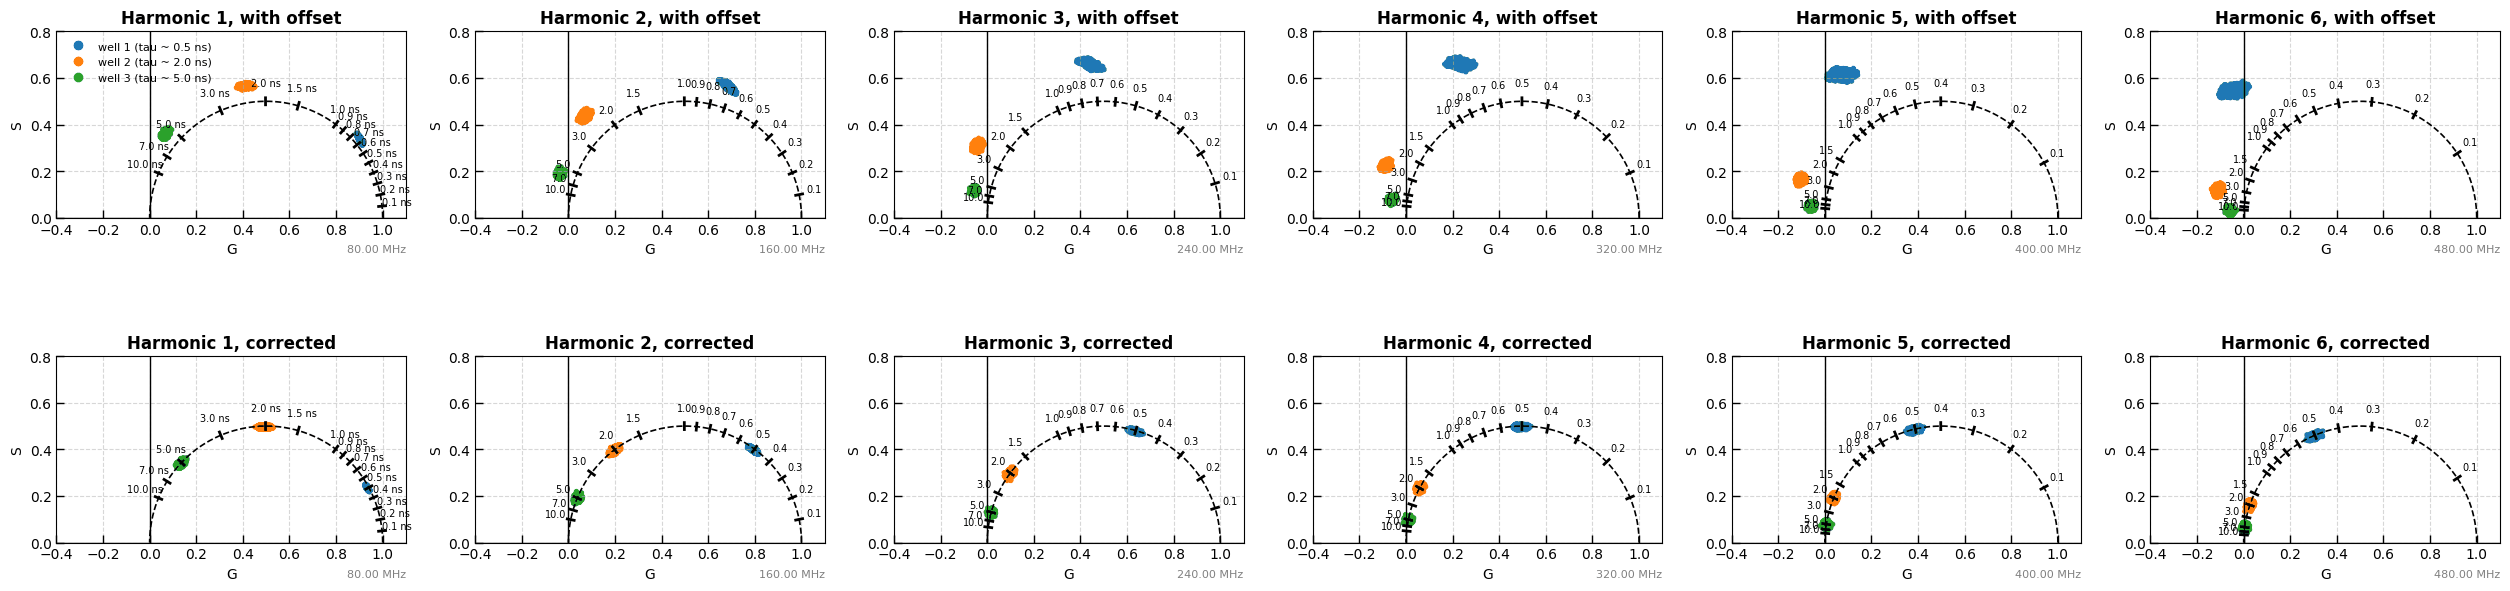

In [4]:
analyzer = PhasorAnalyzer(frequency_hz=LASER_HZ, time_axis_ns=t, n_harmonics=N_HARMONICS)
G, S = analyzer.create_phasor_cpu(decay)
Gc, Sc = analyzer.calibrate(G, S, irf)

result = HarmonicOffset(analyzer).estimate(decay, irf, order=1, v_shift=truth["v_shift_map"])
Gk, Sk = correct_phasors(Gc, Sc, result["t0_map"], LASER_HZ)

well_colors = np.zeros((H, W, 3))
for cid, color in COLORS.items():
    well_colors[img_cluster == cid] = color

fig, axes = plt.subplots(2, N_HARMONICS, figsize=(4.2 * N_HARMONICS, 7))
for row, (g_all, s_all, label) in enumerate([(Gc, Sc, "with offset"), (Gk, Sk, "corrected")]):
    analyzer.plot_phasor_harmonics(
        g_all, s_all, harmonics=tuple(range(1, N_HARMONICS + 1)), mask=mask, colors=well_colors,
        axes=axes[row], xlim=(-0.4, 1.1), ylim=(0.0, 0.8),
    )
    for k, ax in enumerate(axes[row]):
        ax.set_title(f"Harmonic {k + 1}, {label}", fontweight="bold")
axes[0, 0].legend(
    handles=[plt.Line2D([], [], marker="o", linestyle="", color=c, label=well_names[cid]) for cid, c in COLORS.items()],
    frameon=False, fontsize=8, loc="upper left",
)
fig.tight_layout()
plt.show()

## Per-harmonic estimates

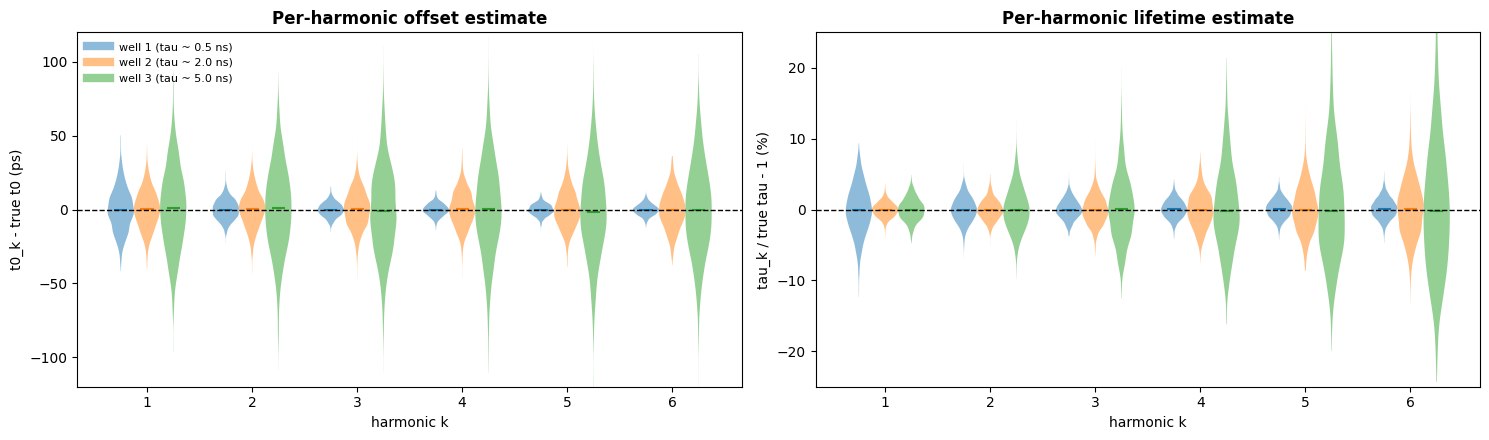

In [5]:
t0_err_ps = 1e3 * (result["t0_k"] - t0_true)
tau_rel = result["tau_k"] / tau_true - 1.0

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
width = 0.25
for j, (cid, color) in enumerate(COLORS.items()):
    sel = img_cluster == cid
    positions = np.arange(1, N_HARMONICS + 1) + (j - 1) * width
    for ax, values in [(axes[0], t0_err_ps), (axes[1], 100 * tau_rel)]:
        parts = ax.violinplot([values[k][sel] for k in range(N_HARMONICS)], positions=positions, widths=width,
                              showmedians=True, showextrema=False)
        for body in parts["bodies"]:
            body.set_facecolor(color)
            body.set_alpha(0.5)
        parts["cmedians"].set_color(color)
    axes[0].plot([], [], color=color, linewidth=6, alpha=0.5, label=well_names[cid])
for ax, label, lim in [(axes[0], "t0_k - true t0 (ps)", 120), (axes[1], "tau_k / true tau - 1 (%)", 25)]:
    ax.axhline(0, color="k", linestyle="--", linewidth=1)
    ax.set_xticks(range(1, N_HARMONICS + 1))
    ax.set_xlabel("harmonic k")
    ax.set_ylabel(label)
    ax.set_ylim(-lim, lim)
axes[0].set_title("Per-harmonic offset estimate", fontweight="bold")
axes[1].set_title("Per-harmonic lifetime estimate", fontweight="bold")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## Precision at each harmonic

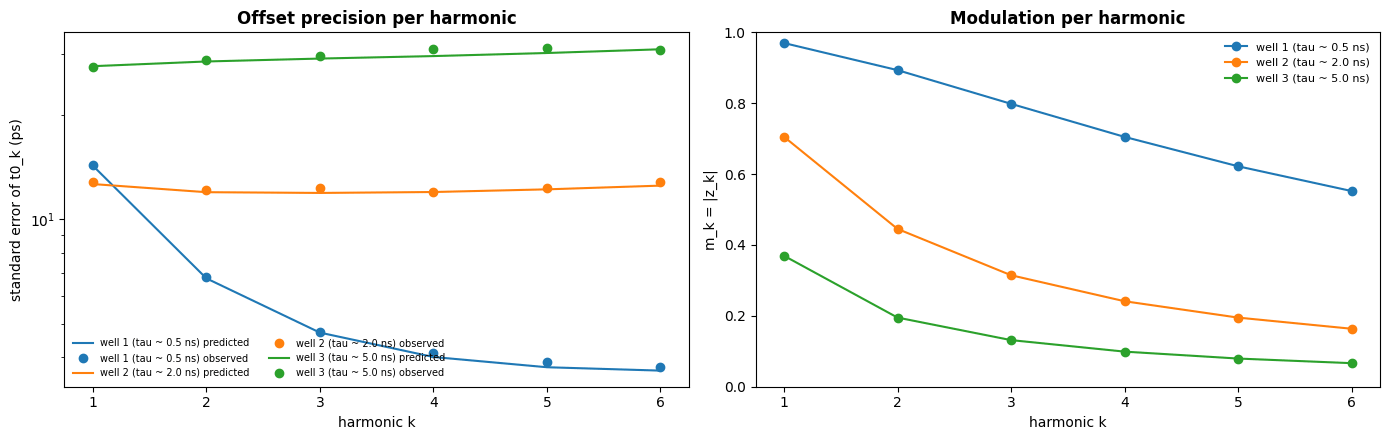

well,well 1 (tau ~ 0.5 ns),well 2 (tau ~ 2.0 ns),well 3 (tau ~ 5.0 ns)
harmonic,,,
1,14.3,12.6,27.7
2,6.8,12.0,28.6
3,4.7,11.9,29.1
4,4.0,12.0,29.6
5,3.7,12.2,30.2
6,3.7,12.5,31.0


In [6]:
predicted_se = 1e3 * np.sqrt(np.moveaxis(np.diagonal(result["cov"], axis1=-2, axis2=-1), -1, 0))
modulation = np.abs(result["z"])
rows = []
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
k_axis = np.arange(1, N_HARMONICS + 1)
for cid, color in COLORS.items():
    sel = img_cluster == cid
    pred = np.array([np.median(predicted_se[k][sel]) for k in range(N_HARMONICS)])
    observed = np.array([np.std(t0_err_ps[k][sel]) for k in range(N_HARMONICS)])
    m_k = np.array([np.median(modulation[k][sel]) for k in range(N_HARMONICS)])
    axes[0].semilogy(k_axis, pred, "-", color=color, label=f"{well_names[cid]} predicted")
    axes[0].semilogy(k_axis, observed, "o", color=color, label=f"{well_names[cid]} observed")
    axes[1].plot(k_axis, m_k, "o-", color=color, label=well_names[cid])
    for k in range(N_HARMONICS):
        rows.append({"well": well_names[cid], "harmonic": k + 1, "m_k": m_k[k],
                     "predicted SE (ps)": pred[k], "observed SD (ps)": observed[k]})
axes[0].set_xlabel("harmonic k")
axes[0].set_ylabel("standard error of t0_k (ps)")
axes[0].set_title("Offset precision per harmonic", fontweight="bold")
axes[0].legend(frameon=False, fontsize=7, ncol=2)
axes[1].set_xlabel("harmonic k")
axes[1].set_ylabel("m_k = |z_k|")
axes[1].set_ylim(0, 1)
axes[1].set_title("Modulation per harmonic", fontweight="bold")
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.set_xticks(k_axis)
fig.tight_layout()
plt.show()
pd.DataFrame(rows).pivot(index="harmonic", columns="well", values="predicted SE (ps)").round(1)

## Combining the harmonics

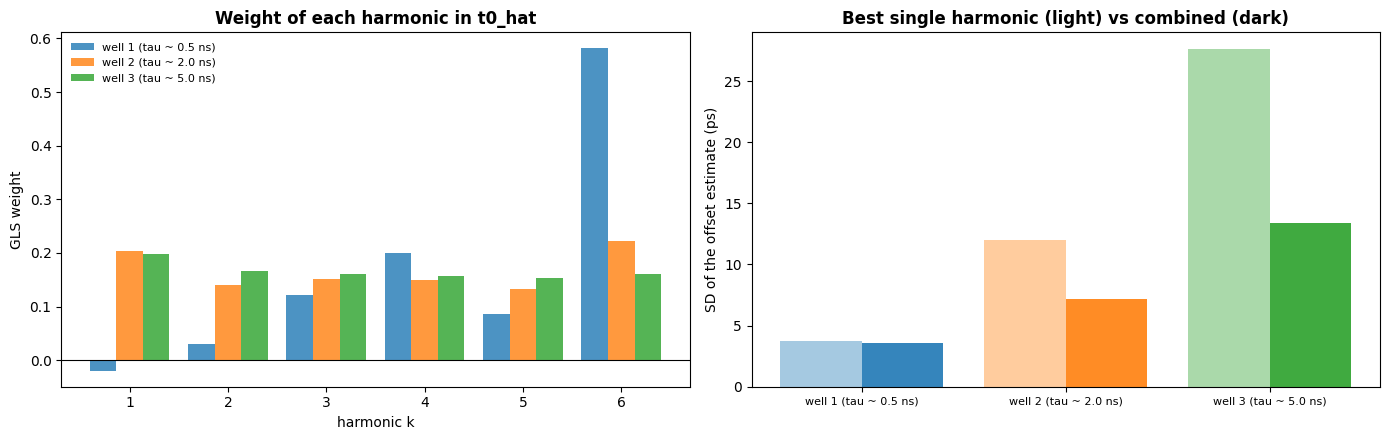

,well 1 (tau ~ 0.5 ns),well 2 (tau ~ 2.0 ns),well 3 (tau ~ 5.0 ns)
weight k=1,-0.019,0.203,0.198
weight k=2,0.031,0.141,0.167
weight k=3,0.121,0.151,0.161
weight k=4,0.201,0.150,0.157
weight k=5,0.086,0.132,0.153
weight k=6,0.581,0.222,0.162
best single harmonic SD (ps),3.751,12.006,27.613
combined SD (ps),3.555,7.193,13.383


In [7]:
cov = result["cov"]
finite = np.isfinite(cov).all(axis=(-2, -1))
weights = np.full((H, W, N_HARMONICS), np.nan)
cinv_one = np.linalg.solve(cov[finite], np.ones((finite.sum(), N_HARMONICS, 1)))[..., 0]
weights[finite] = cinv_one / cinv_one.sum(axis=-1, keepdims=True)
t0_hat_err_ps = 1e3 * (result["t0_hat"] - t0_true)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for j, (cid, color) in enumerate(COLORS.items()):
    sel = img_cluster == cid
    axes[0].bar(k_axis + (j - 1) * 0.27, np.nanmedian(weights[sel], axis=0), width=0.27, color=color,
                alpha=0.8, label=well_names[cid])
    best_single = min(np.std(t0_err_ps[k][sel]) for k in range(N_HARMONICS))
    axes[1].bar(j - 0.2, best_single, width=0.4, color=color, alpha=0.4)
    axes[1].bar(j + 0.2, np.std(t0_hat_err_ps[sel]), width=0.4, color=color, alpha=0.9)
axes[0].axhline(0, color="k", linewidth=0.8)
axes[0].set_xticks(k_axis)
axes[0].set_xlabel("harmonic k")
axes[0].set_ylabel("GLS weight")
axes[0].set_title("Weight of each harmonic in t0_hat", fontweight="bold")
axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xticks(range(3))
axes[1].set_xticklabels([well_names[cid] for cid in COLORS], fontsize=8)
axes[1].set_ylabel("SD of the offset estimate (ps)")
axes[1].set_title("Best single harmonic (light) vs combined (dark)", fontweight="bold")
fig.tight_layout()
plt.show()

pd.DataFrame(
    {
        well_names[cid]: {
            **{f"weight k={k + 1}": np.nanmedian(weights[img_cluster == cid][:, k]) for k in range(N_HARMONICS)},
            "best single harmonic SD (ps)": min(np.std(t0_err_ps[k][img_cluster == cid]) for k in range(N_HARMONICS)),
            "combined SD (ps)": np.std(t0_hat_err_ps[img_cluster == cid]),
        }
        for cid in COLORS
    }
).round(3)

### The chi-square test across harmonics

`chi2 = (t0_k - t0_hat)' C^-1 (t0_k - t0_hat)` measures how well the harmonics agree. For a mono-exponential pixel it follows a chi-square distribution with `K - 1` degrees of freedom whatever the lifetime, so one threshold works for every well; pixels above `chi2_{K-1, 0.95}` are rejected as not mono-exponential.

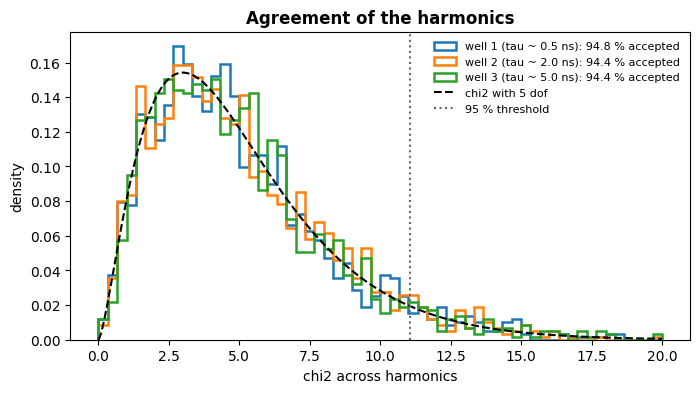

,well 1 (tau ~ 0.5 ns),well 2 (tau ~ 2.0 ns),well 3 (tau ~ 5.0 ns)
mean chi2 (expected 5),5.02,5.10,5.08
accepted (%),94.76,94.39,94.36


In [8]:
grid = np.linspace(0, 20, 400)
fig, ax = plt.subplots(figsize=(8, 4))
for cid, color in COLORS.items():
    sel = img_cluster == cid
    ax.hist(result["chi2"][sel], bins=np.linspace(0, 20, 61), density=True, histtype="step", linewidth=1.8,
            color=color, label=f"{well_names[cid]}: {100 * result['accepted'][sel].mean():.1f} % accepted")
ax.plot(grid, chi2.pdf(grid, N_HARMONICS - 1), "k--", label=f"chi2 with {N_HARMONICS - 1} dof")
ax.axvline(chi2.ppf(0.95, N_HARMONICS - 1), color="0.4", linestyle=":", label="95 % threshold")
ax.set_xlabel("chi2 across harmonics")
ax.set_ylabel("density")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Agreement of the harmonics", fontweight="bold")
plt.show()

pd.DataFrame(
    {
        well_names[cid]: {
            f"mean chi2 (expected {N_HARMONICS - 1})": np.nanmean(result["chi2"][img_cluster == cid]),
            "accepted (%)": 100 * result["accepted"][img_cluster == cid].mean(),
        }
        for cid in COLORS
    }
).round(2)

## Accuracy versus the number of harmonics

How much do the extra harmonics buy? The same data are analysed with `K = 2, 3, ..., 6` harmonics. With more harmonics the per-pixel offset becomes more precise -- most for the long lifetimes, which spread their information over all harmonics -- while staying unbiased, and the offset map fitted to the accepted pixels converges on the truth.

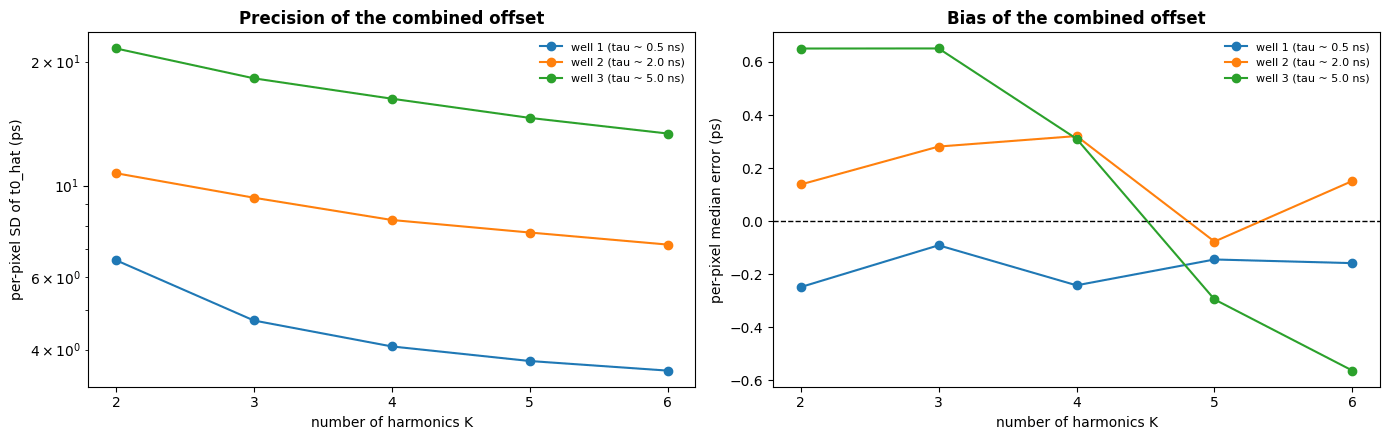

well,well 1 (tau ~ 0.5 ns),well 2 (tau ~ 2.0 ns),well 3 (tau ~ 5.0 ns)
harmonics,,,
2,6.59,10.72,21.53
3,4.71,9.35,18.22
4,4.07,8.25,16.26
5,3.75,7.69,14.60
6,3.56,7.19,13.38


In [9]:
rows = []
for n_harm in range(2, N_HARMONICS + 1):
    analyzer_k = PhasorAnalyzer(frequency_hz=LASER_HZ, time_axis_ns=t, n_harmonics=n_harm)
    result_k = HarmonicOffset(analyzer_k).estimate(decay, irf, order=1, v_shift=truth["v_shift_map"])
    pixel_err = 1e3 * (result_k["t0_hat"] - t0_true)
    map_err = 1e3 * (result_k["h_shift_map"] - h_true)
    for cid in COLORS:
        sel = img_cluster == cid
        rows.append(
            {
                "harmonics": n_harm,
                "well": well_names[cid],
                "per-pixel SD (ps)": np.nanstd(pixel_err[sel]),
                "per-pixel median error (ps)": np.nanmedian(pixel_err[sel]),
                "accepted (%)": 100 * result_k["accepted"][sel].mean(),
                "offset map median error (ps)": np.median(map_err[sel]),
            }
        )
accuracy = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for cid, color in COLORS.items():
    sub = accuracy[accuracy["well"] == well_names[cid]]
    axes[0].semilogy(sub["harmonics"], sub["per-pixel SD (ps)"], "o-", color=color, label=well_names[cid])
    axes[1].plot(sub["harmonics"], sub["per-pixel median error (ps)"], "o-", color=color, label=well_names[cid])
axes[0].set_ylabel("per-pixel SD of t0_hat (ps)")
axes[0].set_title("Precision of the combined offset", fontweight="bold")
axes[1].axhline(0, color="k", linestyle="--", linewidth=1)
axes[1].set_ylabel("per-pixel median error (ps)")
axes[1].set_title("Bias of the combined offset", fontweight="bold")
for ax in axes:
    ax.set_xlabel("number of harmonics K")
    ax.set_xticks(range(2, N_HARMONICS + 1))
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()
accuracy.pivot(index="harmonics", columns="well", values="per-pixel SD (ps)").round(2)

## Offset map and corrected lifetimes

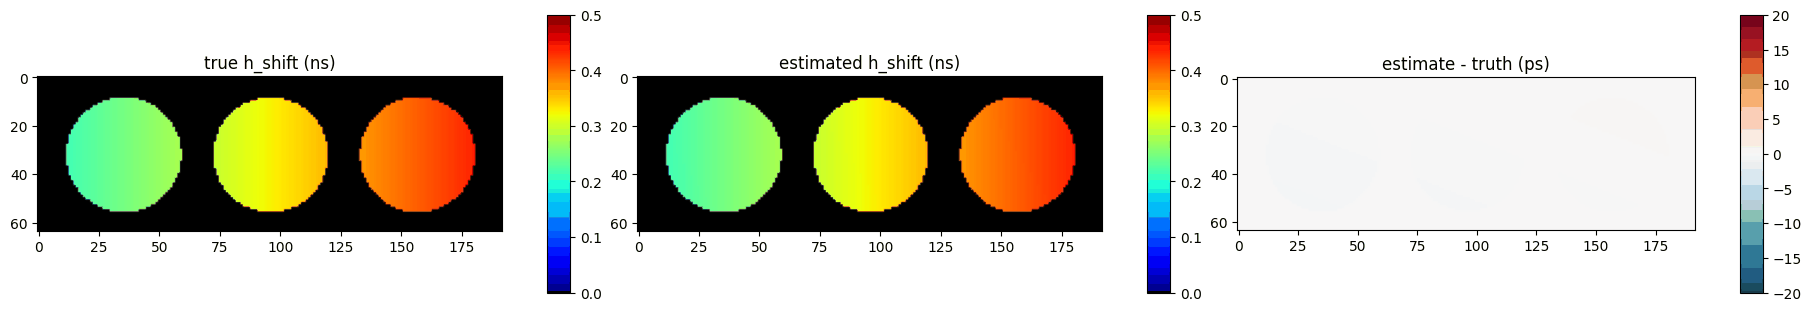

offset error over the field: median -0.05 ps, 5-95 % range 0.49 ps


,true tau,rotation k=1 (deg),phase tau k=1,rotation k=2 (deg),phase tau k=2,rotation k=3 (deg),phase tau k=3,rotation k=4 (deg),phase tau k=4,rotation k=5 (deg),phase tau k=5,rotation k=6 (deg),phase tau k=6
well,,,,,,,,,,,,,
well 1 (tau ~ 0.5 ns),0.500,6.373,0.500,12.746,0.500,19.120,0.500,25.493,0.500,31.866,0.500,38.239,0.500
well 2 (tau ~ 2.0 ns),2.001,8.674,2.001,17.349,1.998,26.023,1.996,34.698,2.008,43.372,1.992,52.046,1.992
well 3 (tau ~ 5.0 ns),5.005,10.976,5.003,21.951,5.027,32.927,4.902,43.902,4.700,54.878,3.616,65.854,2.618


In [10]:
error_ps = 1e3 * (result["h_shift_map"] - h_true)
_ = DataViewer().display_data(
    [np.where(mask, h_true, 0), np.where(mask, result["h_shift_map"], 0), np.where(mask, error_ps, 0)],
    structure=(1, 3),
    coord=None,
    data_names=["true h_shift (ns)", "estimated h_shift (ns)", "estimate - truth (ps)"],
    cmaps=[jet_m, jet_m, "RdBu_r"],
    v_ranges=[(0, 0.5), (0, 0.5), (-20, 20)],
    figsize=(18, 3),
    normalize=False,
    yscale="linear",
)

rows = []
for cid in COLORS:
    sel = img_cluster == cid
    row = {"well": well_names[cid], "true tau": np.median(tau_true[sel])}
    for k in range(N_HARMONICS):
        phi_before = np.unwrap(np.arctan2(Sc[k][sel], Gc[k][sel]))
        phi_after = np.arctan2(Sk[k][sel], Gk[k][sel])
        row[f"rotation k={k + 1} (deg)"] = np.degrees(np.median(phi_before - phi_after))
        row[f"phase tau k={k + 1}"] = np.median(np.tan(phi_after) / ((k + 1) * OMEGA))
    rows.append(row)
summary = pd.DataFrame(rows).set_index("well").round(3)
print(f"offset error over the field: median {np.median(error_ps[mask]):.2f} ps, "
      f"5-95 % range {np.ptp(np.percentile(error_ps[mask], [5, 95])):.2f} ps")
summary